## Innleveringsoppgave uke 38

<div class="alert alert-block alert-info">
Denne notebook filen skal bare lastes opp til Canvas.
Du skal ikke gjøre endringer i denne notebooken!
</div>

### Skriv inn navnet ditt i cellen under

In [1]:
"Bertil Gjendemsjø"

'Bertil Gjendemsjø'

<hr style="border: none; border-top: 2px solid green; margin: 1em 0;">

## Innleveringsoppgave: analyse av antall plantearter

I feltprosjektet samlet dere inn data for Oppgave A som hadde som forskningsspørsmål:

> Hvor stort areal må vi analysere for å få et realistisk bilde av
> artsrikdommen av karplanter i denne plenen?

**a)**
I denne oppgaven skal dere laste inn data fra feltark "Antall arter i en plen".

Start med å lese inn de innsamlede dataene.
Vi velger å lese inn data fra excel filen direkte.
Til det bruker vi Pandas, og funksjonen `pandas.read_xlsx()`.

Merk at i programmet under
* vi antar at du har brukt Excel filen som ble lagt ut på Canvas
* vi hopper over de 7 første radene når vi importerer dataene, fordi de inneholder informasjon som ikke er relevant for analysen,

Fyll inn `"___"` i programmet under:

In [2]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt

filnavn = "BIOS1101_felt_plante_arter_datainnsamling(1).xlsx"
data = pd.read_excel(filnavn, skiprows = 7)
data.head()

,Doblingsfaktor,Antall arter,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6
0,1,3,NaN,NaN,NaN,NaN,NaN
1,2,3,NaN,NaN,NaN,NaN,NaN
2,3,3,NaN,NaN,NaN,NaN,NaN
3,4,4,NaN,NaN,NaN,NaN,NaN
4,5,5,NaN,NaN,NaN,NaN,NaN


**b)**
Dataene fra kolonne 1 `Doblingsfaktor` og kolonne 2 `Antall arter`
skal nå lagres i 2 forskjellige NumPy arrays.
Skriv ut arrayene for å sjekke at de inneholder riktig data.


In [3]:
doblingsfaktor = np.array(data['Doblingsfaktor'])
antall_arter = np.array(data["Antall arter"])

print(f"doblingsfaktor: {doblingsfaktor}, antall arter: {antall_arter}")

doblingsfaktor: [1 2 3 4 5 6 7], antall arter: [3 3 3 4 5 6 6]


**c)**
Lag ett plot av dataene fra disse to kolonnene.

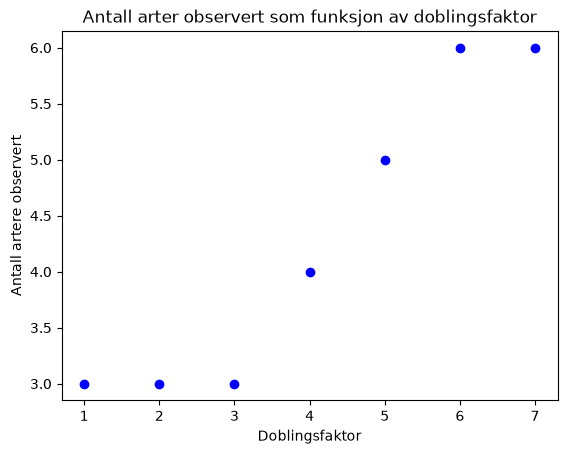

In [4]:
plt.plot(doblingsfaktor, antall_arter, "bo")
plt.title("Antall arter observert som funksjon av doblingsfaktor")
plt.xlabel("Doblingsfaktor")
plt.ylabel("Antall artere observert")
plt.show()

**d)**
Kan du ut fra dataene begrunne eller gi en beskrivelse av hvor stort område
som må undersøkes for å få oversikt over lokalt artsmangfold i plen? Begrunn svaret ditt!


For å estimere rutestørrelsen brukes en tommelfingerregel på at ruten skal inneholde ca. 90% av artene man kan identifisere. Ut fra målingene vi utførte i felt kan vi se at det ikke er forskjell mellom antall arter ved en doblingsfaktor på 6 og 7. Om vi skal forholde oss til regelen tilsier dette at rutestørrelsen vi burde bruke er ca $x = 6$, altså $1,28m^2$.

**e)**
Gjør om arrayet med doblingsfaktorer til et array med arealer kaldt `arealer`.
Bruk NumPy funksjonalitet til å gjøre utregningen.
Husk at det første arealet som ble målt var på $0.04 m^2$.
Skriv ut det nye arrayet.


In [5]:
arealer = 0.04 * 2**(doblingsfaktor-1)
print(f"arealer: {arealer}")

arealer: [0.04 0.08 0.16 0.32 0.64 1.28 2.56]


**f)**
Nå skal du lage en lineær linjetilpasning til dataene.
Bruk `polyfit()`funksjonen for å beregne verdiene
for stigningstall $a$ og skjæringspunkt $b$.
Lag et nytt plott der den linjære tilpasningen plottes sammen med dataene.


Stigningstallet er 1.3044166892931468 og skjæringspunktet er 3.339080459770116


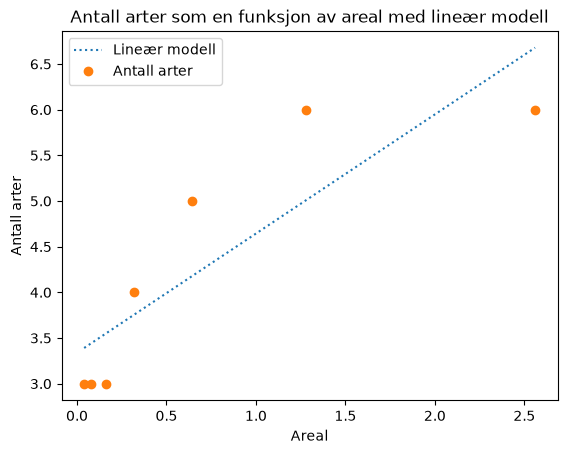

numpy.poly1d

In [6]:
import matplotlib.pyplot as plt

a, b = np.polyfit(arealer, antall_arter, 1)
print(f"Stigningstallet er {a} og skjæringspunktet er {b}")

arealer_fit = np.linspace(min(arealer), max(arealer))
linear_fit = a * arealer_fit + b

plt.plot(arealer_fit, linear_fit, ":", label = "Lineær modell")
plt.plot(arealer, antall_arter, "o", label = "Antall arter")
plt.title("Antall arter som en funksjon av areal med lineær modell")
plt.xlabel("Areal")
plt.ylabel("Antall arter")
plt.legend()
plt.show()

**g)**
Beskriv modellen som her er brukt i tilpasningen og i hvilken grad dette er en god model.


Vi har laget en lineær modell tilpasset målingene våre for å forsøke å beskrive antall arter når arealet av observasjonsruten vokser. Dette er en modell som beskriver at antallet arter øker for hver økning av areal, og ville fortsette å beskrive dette om vi hadde endret lengden på modellen.

Ved visuell inspeksjon av plottet av antall arter som en funksjon av areal og den lineære modellen så kan det ikke konkluderes med at modellen er en god modell for målingene våre. Hverken for de første målingene eller de siste beskriver modellen det forventede antallet arter, og hadde modellen fått en større lengde hadde den beskrevet et enda større antall arter enn målingene peker mot. En sigmoidal kurve antas å være en bedre egnet modell til målingene våre siden de karakteriseres av to flate partier og et parti med hurtig vekst mellom dem.

**h)**
MERK at hvis du har brukt kunstig intelligens til å *besvare hele eller deler av oppgaven for deg*
må du si ifra i cellen under.
Du straffes ikke for dette, men gruppelærere kan velge å ikke gi deg kommentar på (den delen av) innleveringen din.
Du sier dermed fra deg muligheten for å få verdiful tilbakemelding på ditt arbeid,
og påtar deg selv et større ansvar for å oppnå ønsket læring og progresjon i emnet.

KI har ikke blitt brukt for å besvare noen av spørsmålene i innleveringsoppgaven for meg, helt eller delvis. KI har vært brukt som et verktøy i tråd med retningslinjene for KI ved UiO og de veiledende artiklene som ligger på UiOs nettsider om bruk av KI i utdanningssammenheng. KI-programvarens innstillinger for deling av data er avskrudd.

Modellene jeg har brukt har fått tydelige og detaljerte instruksjoner om å ikke gi svar, men heller være en medelev og veileder som skal komme med råd, finne årsaken til at jeg ikke kommer videre med en oppgave eller forklare problemstillinger på andre måter. Om ønskelig kan disse instruksjonene fremvises for å bekrefte at dette stemmer.

Kodeskriptene har vært korrigert i form av opplysning om visse funksjoners virkemåte, påpekelser av slurvefeil i kopiering av gammel kode som inneholdt andre variabler, påminnelser om å alltid markere plots samt korrigering av feilmarkerte plots, henvisning til relevante områder av faglitteratur innen matematikk for veiledning.

Tekstbesvarelsene har et par tilfeller av språkvask, grammatiske rettelser og retting av uryddige forklaringer.

Jeg har brukt følgende KI-modeller:
"Claude Sonnet 5" fra Anthropic.
"Claude Opus 5" fra Anthropic.

**i)**
Egenvurdering - frivillig:

Hvordan var det å jobbe med denne oppgaven?
Hva mestrer du, hva er fortsatt utfordrende?

Jeg synes oppgaven var grei og dekket det mest relevante vi hadde lært i uke 38. Jeg hadde likt godt om pensum fra tidligere uker ble brukt mer sammenflettet i oppgaven for å repetere det vi har gått gjennom tidligere. Jeg føler også at jeg ikke helt skjønner hvorfor vi blir bedt om å bruke øyemål på både denne oppgaven og tidligere oppgavesett for å vurdere om en modell er gyldig når vi heller kan bruke matte eller funksjoner i numpy eller scipy bibliotekene for å finne svaret, om så som en ikke-tellende ekstraoppgave.